# Plotting geospatial data with git branching
## Week 5 Discussion Section

## Steps
1. Read CSVs with `pandas`, read the shapfile with `geopandas`
2. Check column types, ,missing values, and the type column
3. Filter to earthquakes w/ mag >= 6.5
4. Built point geometries with latitude and longitude
5. Assessing CRS EPSG: 4326 and confirm it matches the countries layer
6. Plot countries first, then earthquake points


In [31]:
import os
import pandas as pd
import numpy as np 
import geopandas as gpd 
import matplotlib.pyplot as plt

earth_csv = os.path.join('data', 'earthquake_data.csv')
countries_file = os.path.join('data/countries_file', 'ne_110m_admin_0_countries.shp')

earthquakes = pd.read_csv(earth_csv)
countries = gpd.read_file(countries_file)

In [32]:
earthquakes.columns

Index(['time', 'latitude', 'longitude', 'depth', 'mag', 'id', 'place', 'type'], dtype='object')

In [33]:
earthquakes.isna().value_counts()

time   latitude  longitude  depth  mag    id     place  type 
False  False     False      False  False  False  False  False    120065
                                   True   False  False  False        42
                            True   True   False  False  False         1
Name: count, dtype: int64

In [34]:
earthquakes['mag'].describe()

count    120065.000000
mean          1.793958
std           1.343466
min          -0.970000
25%           0.820000
50%           1.400000
75%           2.400000
max           8.200000
Name: mag, dtype: float64

In [35]:
earthquakes['type'].unique()

array(['earthquake', 'quarry blast', 'quarry', 'mining explosion',
       'rock burst', 'explosion', 'landslide', 'sonicboom', 'sonic boom',
       'anthropogenic event', 'acoustic noise'], dtype=object)

### Filter for earthquakes greater than or equal to mag 6.5

In [40]:
earthquakes = earthquakes[earthquakes['type'] == "earthquake"]
quakes_65 = earthquakes[earthquakes['mag'] >= 6.5]

### Create point geometries to plot quakes

In [41]:
countries.head()


,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180.00000 -16.06713, 180.00000..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95000, 34.07262 -1.05982..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84000 49.00000, -122.9742..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84000 49.00000, -120.0000..."


In [47]:
eq_points = gpd.GeoDataFrame(
    quakes_65, 
    geometry = gpd.points_from_xy(quakes_65['longitude'], quakes_65['latitude']),
    crs = 'EPSG:4326'
)
eq_points.head()

,time,latitude,longitude,depth,mag,id,place,type,geometry
9062,2014-01-01 16:03:29.000,-13.8633,167.2490,187.00,6.5,usc000lvb5,"32km W of Sola, Vanuatu",earthquake,POINT (167.24900 -13.86330)
12142,2014-02-18 09:27:13.120,14.6682,-58.9272,14.83,6.5,usc000mskt,"172km NNE of Bathsheba, Barbados",earthquake,POINT (-58.92720 14.66820)
14025,2014-02-12 09:19:49.060,35.9053,82.5864,10.00,6.9,usc000mnvj,"272km ESE of Hotan, China",earthquake,POINT (82.58640 35.90530)
15979,2014-02-07 08:40:13.550,-15.0691,167.3721,122.00,6.5,usc000mjye,"34km E of Port-Olry, Vanuatu",earthquake,POINT (167.37210 -15.06910)
17606,2014-02-02 09:26:37.820,-32.9076,-177.8806,44.26,6.5,usc000mfm0,"189km SSE of L'Esperance Rock, New Zealand",earthquake,POINT (-177.88060 -32.90760)


In [48]:
eq_points.crs == countries.crs

True

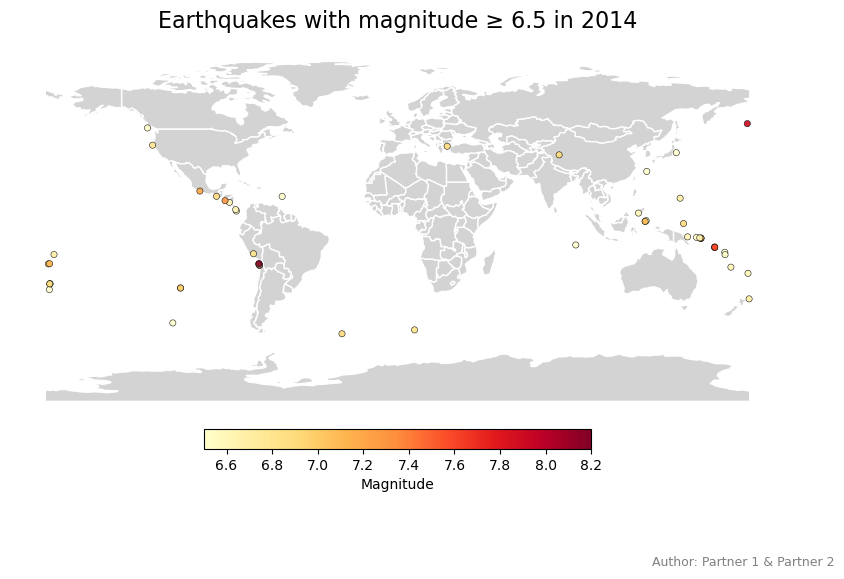

In [55]:
fig, ax = plt.subplots(figsize=(10, 7))

# Basemap: countries in light gray with white borders
countries.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=1)

# Earthquakes colored by magnitude
eq_points.plot(
    ax=ax,
    column='mag',
    cmap='YlOrRd',
    markersize=20,
    edgecolor='black',
    linewidth=0.4,
    alpha=0.9,
    legend=True,
    legend_kwds={'label': 'Magnitude', 'orientation': 'horizontal', 'shrink': 0.5, 'pad': 0.02}
)

ax.set_title('Earthquakes with magnitude ≥ 6.5 in 2014', fontsize=16, pad=12)
ax.set_axis_off()

# Section 4 of the discussion: each partner adds their name on their own branch.
plt.figtext(0.95, 0.03, 'Author: Partner 1 & Partner 2', ha='right', fontsize=9, color='gray')

plt.show()